# Лабораторная работа 4. Бонус — Проверка данных на нормальность

**ФИО:** Иноземцев Сергей Викторович  
**Группа:** ЕТ-216

Цель: реализовать функцию Gauss с критерием χ² Пирсона и исследовать распределения Iris.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 25)
pd.set_option('display.max_rows', 25)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.figsize': (9, 5), 'figure.dpi': 110})
DATA = Path('.')
FIG = Path('figures')
FIG.mkdir(exist_ok=True)

def show(name):
    plt.tight_layout()
    plt.savefig(FIG / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close('all')


## Бонус Iris Функция Gauss
H0: признак имеет нормальное распределение с оценёнными μ и σ; H1: распределение отличается. Критерий χ² Пирсона строится по равновероятным интервалам нормального распределения с крайними границами ±∞. Ожидаемая частота не меньше 5. Два параметра оценены по выборке, поэтому ddof=2 и число степеней свободы k−3. Применимость асимптотического приближения ограничена, особенно при малых выборках и округлении измерений.

,Ширина лепестка,Длина лепестка,Ширина чашелистика,Длина чашелистика
1,0.2,1.4,3.5,5.1
2,0.2,1.4,3.0,4.9
3,0.2,1.3,3.2,4.7
4,0.2,1.5,3.1,4.6
5,0.2,1.4,3.6,5.0


Ширина лепестка n= 150 mean= 1.1993333333333336 median= 1.3 skew= -0.1029667476489812 excess= -1.340603996612645
H0: нормальность; H1: не нормальность; χ²= 59.06666666666666 df= 5 p= 1.8946730414722948e-11 ; H0 отклонена


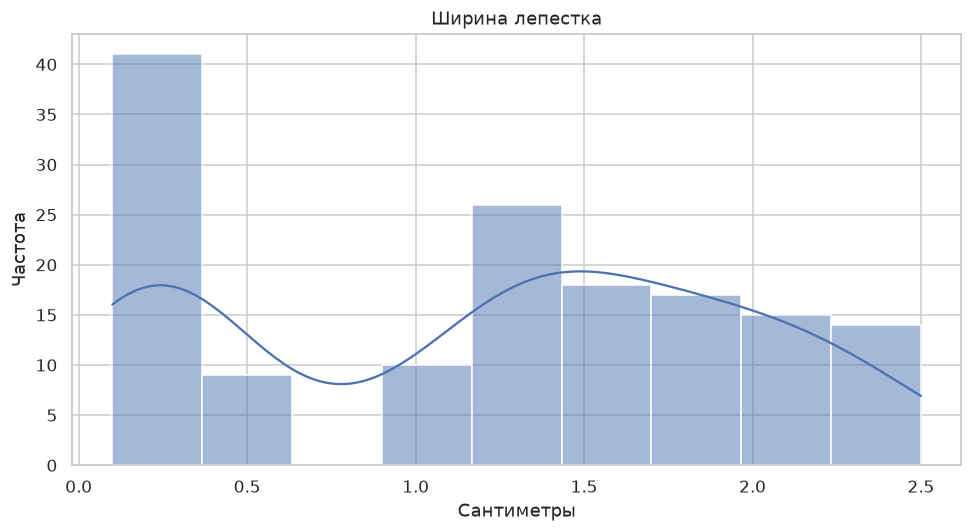

Длина лепестка n= 150 mean= 3.7580000000000005 median= 4.35 skew= -0.2748841797510128 excess= -1.4021034155217516
H0: нормальность; H1: не нормальность; χ²= 98.85333333333332 df= 5 p= 9.219114983995426e-20 ; H0 отклонена


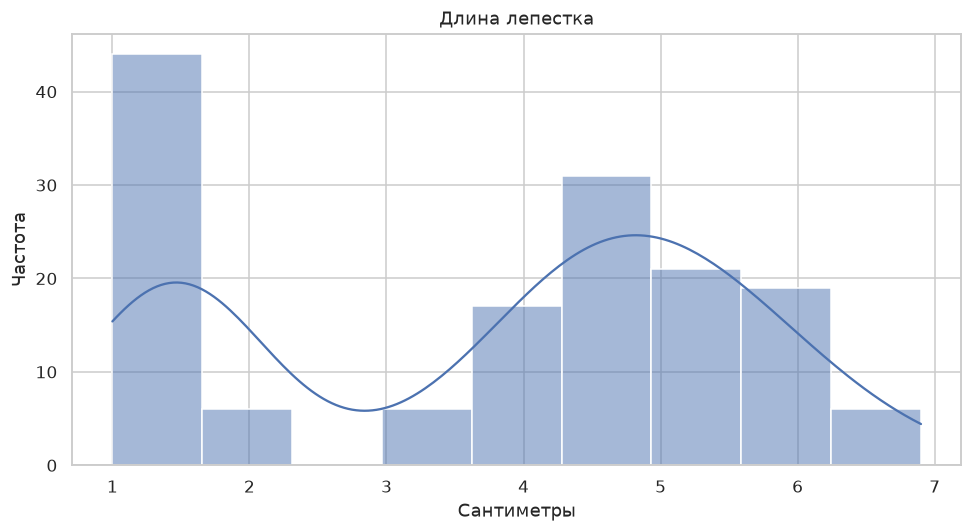

Ширина чашелистика n= 150 mean= 3.0573333333333337 median= 3.0 skew= 0.3189656647135998 excess= 0.2282490424681929
H0: нормальность; H1: не нормальность; χ²= 8.72 df= 5 p= 0.12076725712024744 ; H0 не отклонена


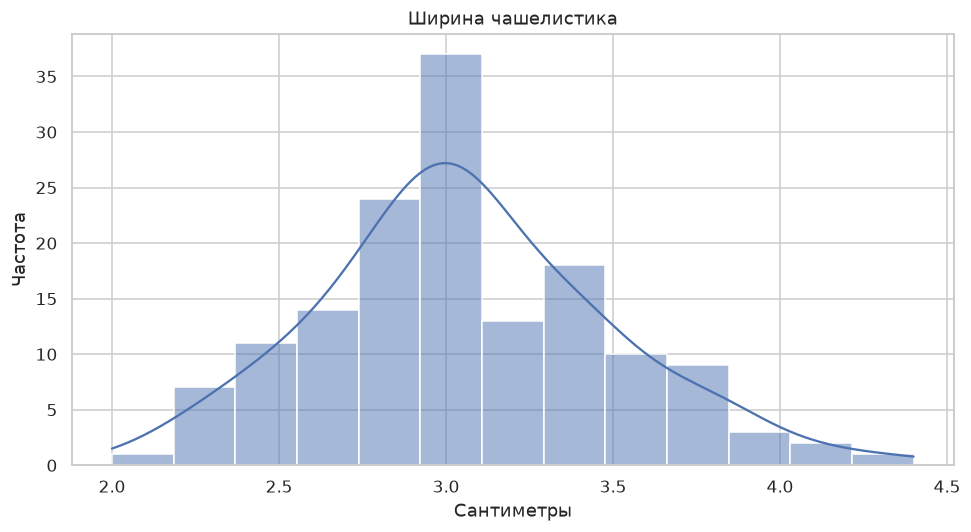

Длина чашелистика n= 150 mean= 5.843333333333334 median= 5.8 skew= 0.3149109566369729 excess= -0.5520640413156395
H0: нормальность; H1: не нормальность; χ²= 10.64 df= 5 p= 0.05900384824545067 ; H0 не отклонена


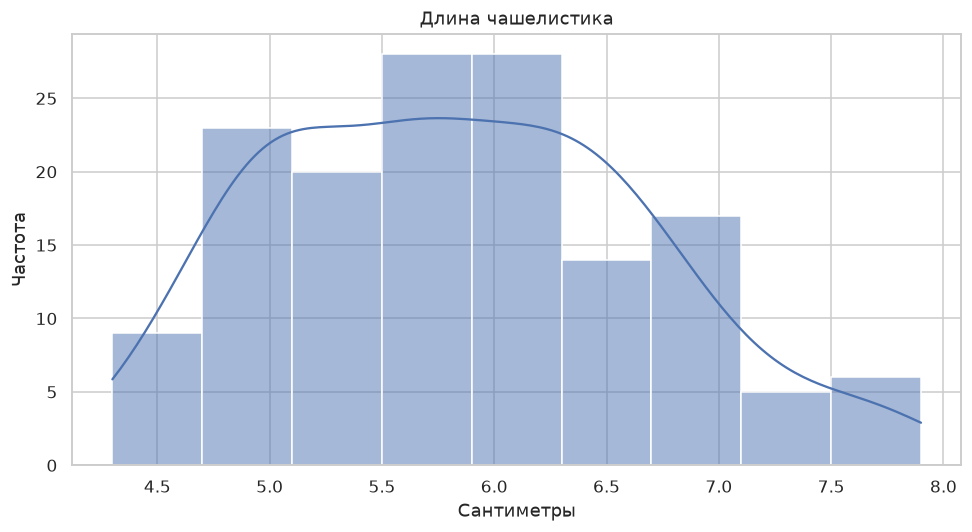

Ширина лепестка       1.894673e-11
Длина лепестка        9.219115e-20
Ширина чашелистика    1.207673e-01
Длина чашелистика     5.900385e-02
Name: p χ², dtype: float64

Минимальное p для: Длина лепестка
Длина лепестка Setosa n= 50 mean= 1.4620000000000002 median= 1.5 skew= 0.1063938996982434 excess= 1.0215761065826152
H0: нормальность; H1: не нормальность; χ²= 4.4 df= 2 p= 0.11080315836233386 ; H0 не отклонена


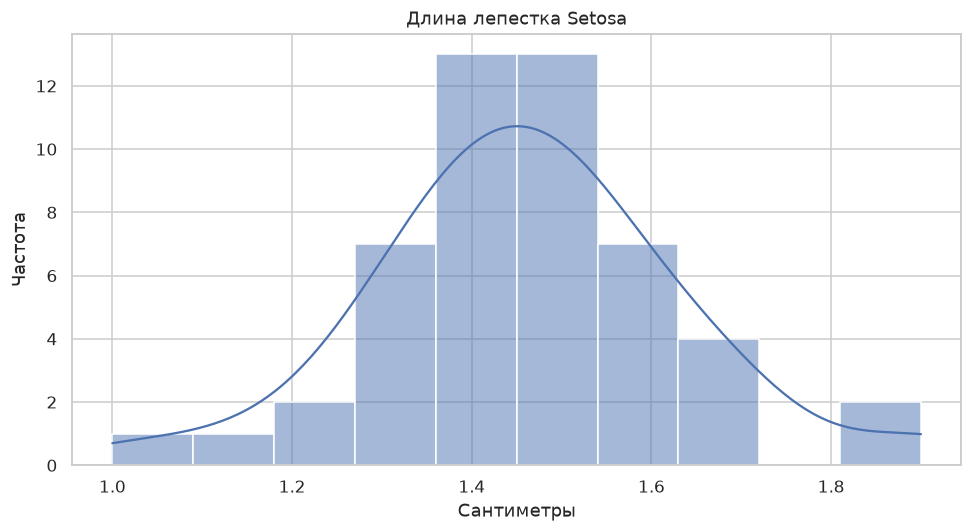

Длина лепестка Verginica n= 50 mean= 5.5520000000000005 median= 5.55 skew= 0.5494445890270053 excess= -0.1537785609504292
H0: нормальность; H1: не нормальность; χ²= 1.2000000000000002 df= 2 p= 0.5488116360940265 ; H0 не отклонена


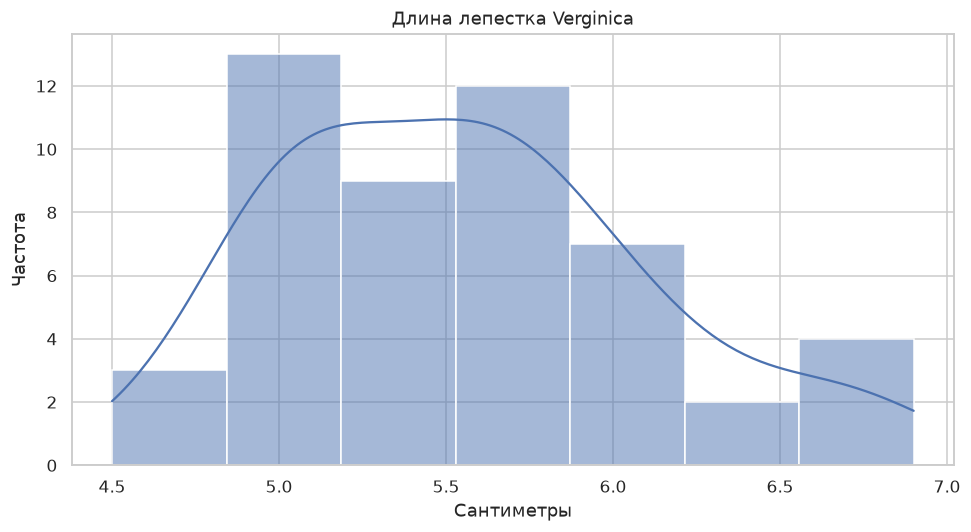

Длина лепестка Versicolor n= 50 mean= 4.26 median= 4.35 skew= -0.606507689490624 excess= 0.047903299627571005
H0: нормальность; H1: не нормальность; χ²= 3.8000000000000003 df= 2 p= 0.14956861922263504 ; H0 не отклонена


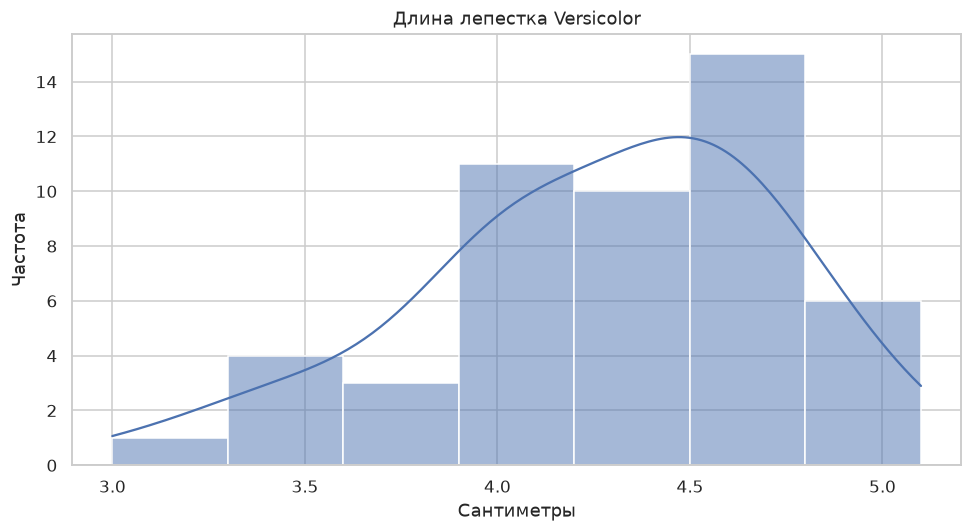

Длина лепестка мелкие Setosa n= 50 mean= 1.4620000000000002 median= 1.5 skew= 0.1063938996982434 excess= 1.0215761065826152
H0: нормальность; H1: не нормальность; χ²= 4.4 df= 2 p= 0.11080315836233386 ; H0 не отклонена


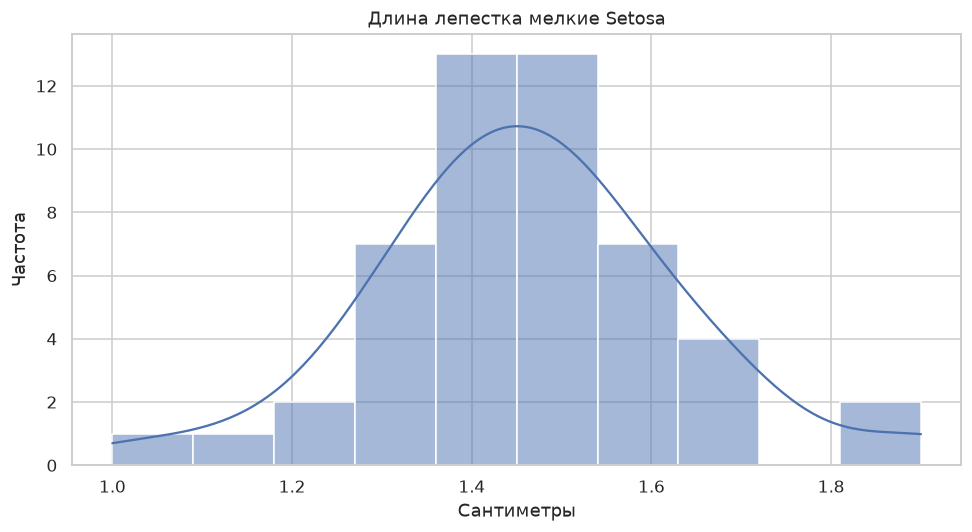

Длина лепестка крупные два сорта n= 100 mean= 4.906 median= 4.9 skew= 0.17107351966707676 excess= -0.32483353668775194
H0: нормальность; H1: не нормальность; χ²= 4.96 df= 5 p= 0.4207813477767336 ; H0 не отклонена


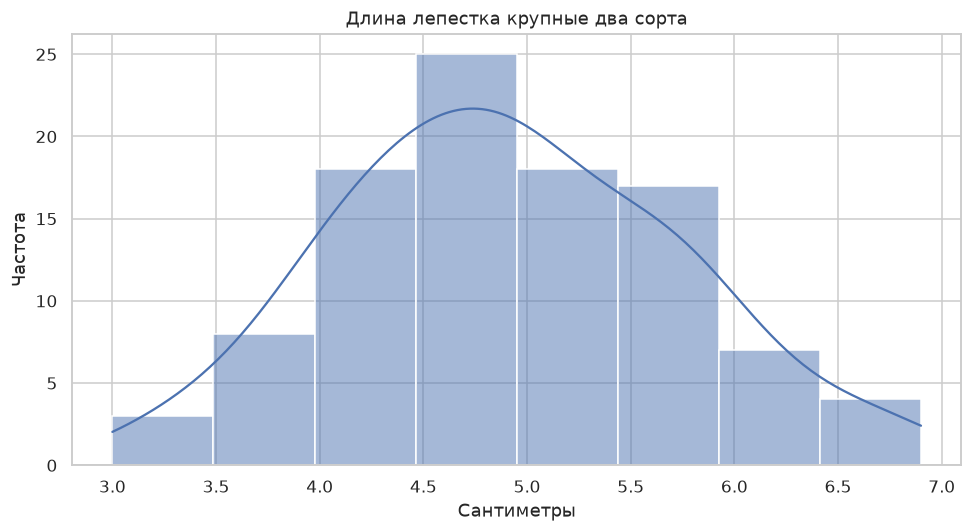

In [2]:
iris_raw=pd.read_excel(DATA/'Iris.xlsx',sheet_name='Data')
iris_raw['Species_name']=iris_raw['Species_name'].str.strip()
translations={'Petal_width':'Ширина лепестка','Petal_length':'Длина лепестка','Sepal_width':'Ширина чашелистика','Sepal_length':'Длина чашелистика'}
iris=iris_raw.drop(columns=['Species_No','Species_name']).rename(columns=translations);iris.index=np.arange(1,151);display(iris.head())
def Gauss(x,name):
    x=np.asarray(pd.Series(x).dropna(),dtype=float);n=len(x);k=min(8,n//10)
    mu=x.mean();sigma=x.std(ddof=0)
    if k<4 or sigma<=0:raise ValueError('Недостаточно данных для χ² с двумя оценёнными параметрами')
    edges=stats.norm.ppf(np.linspace(0,1,k+1),loc=mu,scale=sigma)
    observed,_=np.histogram(x,bins=edges);expected=np.full(k,n/k)
    chi,p=stats.chisquare(observed,expected,ddof=2)
    print(name,'n=',n,'mean=',mu,'median=',np.median(x),'skew=',stats.skew(x,bias=False),'excess=',stats.kurtosis(x,bias=False))
    print('H0: нормальность; H1: не нормальность; χ²=',chi,'df=',k-3,'p=',p,'; H0', 'отклонена' if p<.05 else 'не отклонена')
    sns.histplot(x,kde=True);plt.title(name);plt.xlabel('Сантиметры');plt.ylabel('Частота');show('iris_'+str(Gauss.counter));Gauss.counter+=1
    return p
Gauss.counter=0
iris_p={c:Gauss(iris[c],c) for c in iris.columns};display(pd.Series(iris_p,name='p χ²'))
worst=min(iris_p,key=iris_p.get);original=next(k for k,v in translations.items() if v==worst)
print('Минимальное p для:', worst)
species_p={species: Gauss(part[original], worst+' '+species) for species,part in iris_raw.groupby('Species_name')}
small_p=Gauss(iris_raw.loc[iris_raw.Species_name.eq('Setosa'),original],worst+' мелкие Setosa')
large_p=Gauss(iris_raw.loc[~iris_raw.Species_name.eq('Setosa'),original],worst+' крупные два сорта')

## Общий вывод
Смесь сортов может быть ненормальной даже при близких к нормальным распределениях отдельных сортов. Функция проверяет каждый сорт и объединение двух крупных сортов отдельно; результаты приведены непосредственно над выводом. Неотклонение нормальности не означает её доказанности. Во всех сравнениях нужно учитывать размер эффекта, выбор метода и множественность проверок, а не только порог 0,05.

In [3]:
print('Выбранный признак:', worst)
for group, p in {**species_p, 'Мелкие (Setosa)': small_p, 'Крупные (два сорта)': large_p}.items():
    print(f"{group}: p={p:.6g}; H0 {'отклонена' if p < .05 else 'не отклонена'}.")


Выбранный признак: Длина лепестка
Setosa: p=0.110803; H0 не отклонена.
Verginica: p=0.548812; H0 не отклонена.
Versicolor: p=0.149569; H0 не отклонена.
Мелкие (Setosa): p=0.110803; H0 не отклонена.
Крупные (два сорта): p=0.420781; H0 не отклонена.
